## Problem Statement:

Jamboree has helped thousands of students like you make it to top colleges abroad. Be it GMAT, GRE or SAT, their unique problem-solving methods ensure maximum scores with minimum effort.
They recently launched a feature where students/learners can come to their website and check their probability of getting into the IVY league college. This feature estimates the chances of graduate admission from an Indian perspective.

By doing data analysis help Jamboree in understanding what factors are important in graduate admissions and how these factors are interrelated among themselves. It will also help predict one's chances of admission given the rest of the variables.


## Import Libraries

In [1]:
# importing relevant libraries
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression,Lasso,Ridge

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import statsmodels.api as sm
import scipy.stats as stats

##  Load the Dataset

In [2]:
# load the dataset
data = pd.read_csv('Jamboree_Admission.csv')

# view top 5 rows of the data
data.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


In [3]:
# view bottom 5 rows of the data
data.tail()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
495,496,332,108,5,4.5,4.0,9.02,1,0.87
496,497,337,117,5,5.0,5.0,9.87,1,0.96
497,498,330,120,5,4.5,5.0,9.56,1,0.93
498,499,312,103,4,4.0,5.0,8.43,0,0.73
499,500,327,113,4,4.5,4.5,9.04,0,0.84


In [4]:
# check variable names
data.columns

Index(['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP',
       'LOR ', 'CGPA', 'Research', 'Chance of Admit '],
      dtype='object')

In [5]:
# cleaning extra spaces in the variable names
data.columns = data.columns.str.strip()
print(data.columns)

Index(['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP',
       'LOR', 'CGPA', 'Research', 'Chance of Admit'],
      dtype='object')


In [6]:
# dropping redundant column
data = data.drop(['Serial No.'], axis = 1)
data.head()

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,337,118,4,4.5,4.5,9.65,1,0.92
1,324,107,4,4.0,4.5,8.87,1,0.76
2,316,104,3,3.0,3.5,8.00,1,0.72
3,322,110,3,3.5,2.5,8.67,1,0.80
4,314,103,2,2.0,3.0,8.21,0,0.65


**Data dimension**

In [7]:
# shape of the data
data.shape

(500, 8)

In [8]:
# concise data info
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   GRE Score          500 non-null    int64  
 1   TOEFL Score        500 non-null    int64  
 2   University Rating  500 non-null    int64  
 3   SOP                500 non-null    float64
 4   LOR                500 non-null    float64
 5   CGPA               500 non-null    float64
 6   Research           500 non-null    int64  
 7   Chance of Admit    500 non-null    float64
dtypes: float64(4), int64(4)
memory usage: 31.4 KB


In [9]:
# check datatypes
data.dtypes

GRE Score              int64
TOEFL Score            int64
University Rating      int64
SOP                  float64
LOR                  float64
CGPA                 float64
Research               int64
Chance of Admit      float64
dtype: object

In [10]:
# unique values count
data.nunique()

GRE Score             49
TOEFL Score           29
University Rating      5
SOP                    9
LOR                    9
CGPA                 184
Research               2
Chance of Admit       61
dtype: int64

**Missing value Detection**

In [11]:
# check missing values
data.isnull().sum()

GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
Chance of Admit      0
dtype: int64

**Statistical Summary**

In [12]:
# check stats summary
data.describe()

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
count,500.000000,500.000000,500.000000,500.000000,500.00000,500.000000,500.000000,500.00000
mean,316.472000,107.192000,3.114000,3.374000,3.48400,8.576440,0.560000,0.72174
std,11.295148,6.081868,1.143512,0.991004,0.92545,0.604813,0.496884,0.14114
min,290.000000,92.000000,1.000000,1.000000,1.00000,6.800000,0.000000,0.34000
25%,308.000000,103.000000,2.000000,2.500000,3.00000,8.127500,0.000000,0.63000
50%,317.000000,107.000000,3.000000,3.500000,3.50000,8.560000,1.000000,0.72000
75%,325.000000,112.000000,4.000000,4.000000,4.00000,9.040000,1.000000,0.82000
max,340.000000,120.000000,5.000000,5.000000,5.00000,9.920000,1.000000,0.97000


## Exploratory Data Analysis

### Univariate Analysis

**Chance of Admit**

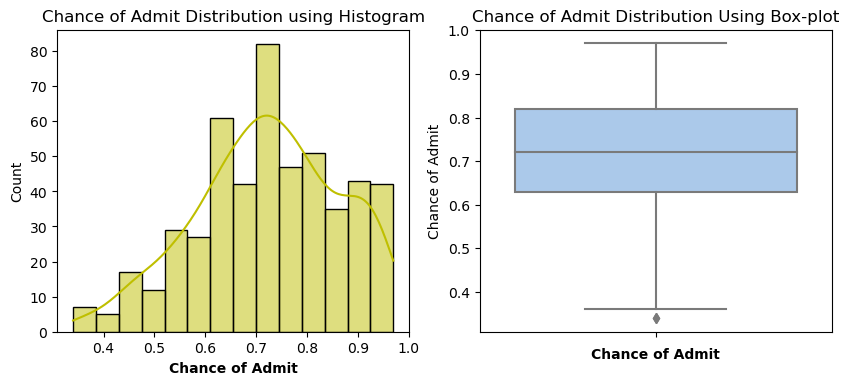

In [13]:
col = 'Chance of Admit'

# setting figure size
plt.figure(figsize = (10,4), dpi = 100)
# creating first subplot - histplot
plt.subplot(121)

# plotting histogram
sns.histplot(data[col], color = 'y', kde = True)
# providing title to the graph
plt.title(col+ ' ' + 'Distribution using Histogram', fontsize = 12)
# setting name of xlabel
plt.xlabel(col, fontsize = 10, weight = 'bold')


# creating second subplot - Boxplot
plt.subplot(122)
# creating boxplot
sns.boxplot(y = data[col], palette = 'pastel')
# providing title to the graph
plt.title(col+ ' ' + 'Distribution Using Box-plot', fontsize = 12)
# setting name of xlabel
plt.xlabel(col, fontsize = 10, fontweight = 'bold')

# showing the plot
plt.show()

**`Observations :`**
+ From the histogram, we can see that the distribution of the "chance of admit in college" variable is left-skewed. 
+ The range of distribution of variable "chance of admit" is 0.629 which is difference of highest value(0.97) and lowest value (0.34) of the variable.
+ From the boxplot, we can see that the median chance of admit is around 0.72.
+ Outliers are present below the whiskers, indicating the presence of extreme values in the "Chance of Admit" variable.

**GRE Score**

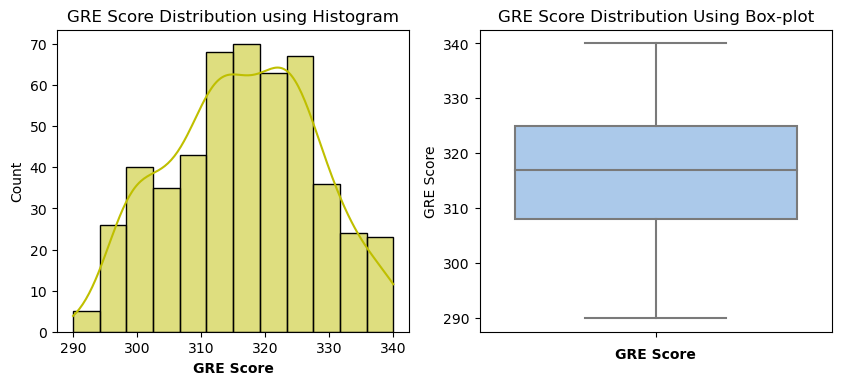

In [14]:
col = 'GRE Score'

# setting figure size
plt.figure(figsize = (10,4), dpi = 100)
# creating first subplot - histplot
plt.subplot(121)

# plotting histogram
sns.histplot(data[col], color = 'y', kde = True)
# providing title to the graph
plt.title(col+ ' ' + 'Distribution using Histogram', fontsize = 12)
# setting name of xlabel
plt.xlabel(col, fontsize = 10, weight = 'bold')


# creating second subplot - Boxplot
plt.subplot(122)
# creating boxplot
sns.boxplot(y = data[col], palette = 'pastel')
# providing title to the graph
plt.title(col+ ' ' + 'Distribution Using Box-plot', fontsize = 12)
# setting name of xlabel
plt.xlabel(col, fontsize = 10, fontweight = 'bold')

# showing the plot
plt.show()

**`Observations :`**
+ From the histogram, we can see that the distribution of the "GRE score" variable is somewhat normal. 
+ The range of distribution of variable "GRE Score" is 50 which is difference of highest value(340) and lowest value (290) of the variable.
+ From the boxplot, we can see that the median GRE Score is around 317.
+ The boxplot also shows that there is no outlier in the variable - 'GRE Score'.

**TOEFL Score**

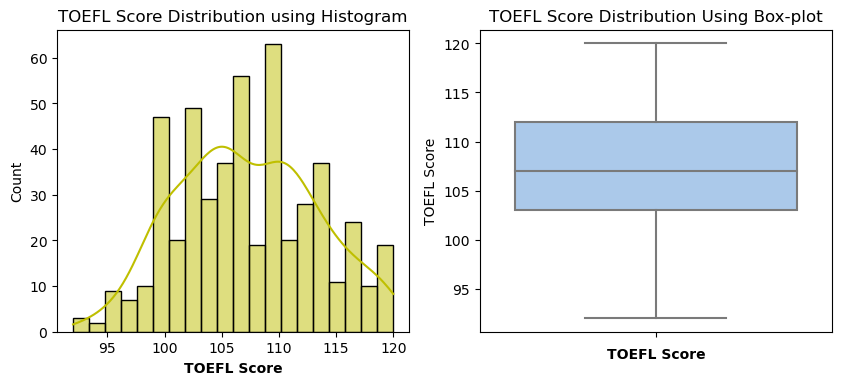

In [15]:
col = 'TOEFL Score'

# setting figure size
plt.figure(figsize = (10,4), dpi = 100)
# creating first subplot - histplot
plt.subplot(121)

# plotting histogram
sns.histplot(data[col], color = 'y', kde = True, bins = 20)
# providing title to the graph
plt.title(col+ ' ' + 'Distribution using Histogram', fontsize = 12)
# setting name of xlabel
plt.xlabel(col, fontsize = 10, weight = 'bold')


# creating second subplot - Boxplot
plt.subplot(122)
# creating boxplot
sns.boxplot(y = data[col], palette = 'pastel')
# providing title to the graph
plt.title(col+ ' ' + 'Distribution Using Box-plot', fontsize = 12)
# setting name of xlabel
plt.xlabel(col, fontsize = 10, fontweight = 'bold')

# showing the plot
plt.show()

**`Observations :`**
+ From the histogram, we can see that the distribution of the "TOEFL score" variable is somewhat normal. 
+ The range of distribution of variable "TOEFL score" is 28 which is difference of highest value(120) and lowest value (92) of the variable.
+ From the boxplot, we can see that the median TOEFL score is around 107.
+ The boxplot also shows that there is no outlier in the variable - 'TOEFL score'.

**University Rating**
  

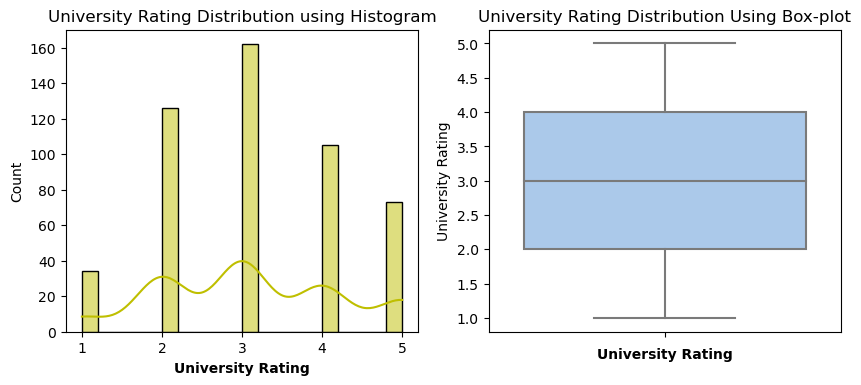

In [16]:
col = 'University Rating'

# setting figure size
plt.figure(figsize = (10,4), dpi = 100)

# creating first subplot - histplot
plt.subplot(121)
# plotting histogram
sns.histplot(data[col], color = 'y', kde = True, bins = 20)
# providing title to the graph
plt.title(col+ ' ' + 'Distribution using Histogram', fontsize = 12)
# setting name of xlabel
plt.xlabel(col, fontsize = 10, weight = 'bold')


# creating second subplot - Boxplot
plt.subplot(122)
# creating boxplot
sns.boxplot(y = data[col], palette = 'pastel')
# providing title to the graph
plt.title(col+ ' ' + 'Distribution Using Box-plot', fontsize = 12)
# setting name of xlabel
plt.xlabel(col, fontsize = 10, fontweight = 'bold')

# showing the plot
plt.show()

**`Observations :`**
+  The histogram shows the distribution of University ratings on a scale of 1 to 5. 
+ Ratings of 3 is most common, while ratings of 1 is least common.
+ The boxplot also shows that there is no outlier in the University rating variable.

**SOP**

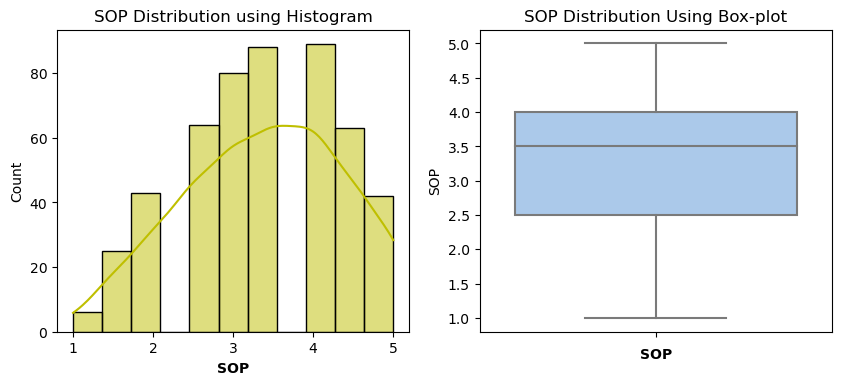

In [17]:
col = 'SOP'

# setting figure size
plt.figure(figsize = (10,4), dpi = 100)
# creating first subplot - histplot
plt.subplot(121)

# plotting histogram
sns.histplot(data[col], color = 'y', kde = True)
# providing title to the graph
plt.title(col+ ' ' + 'Distribution using Histogram', fontsize = 12)
# setting name of xlabel
plt.xlabel(col, fontsize = 10, weight = 'bold')


# creating second subplot - Boxplot
plt.subplot(122)
# creating boxplot
sns.boxplot(y = data[col], palette = 'pastel')
# providing title to the graph
plt.title(col+ ' ' + 'Distribution Using Box-plot', fontsize = 12)
# setting name of xlabel
plt.xlabel(col, fontsize = 10, fontweight = 'bold')

# showing the plot
plt.show()

**`Observations :`**
+ From the histogram, we can see that the distribution of the "SOP" variable is left skewed. 
+ The range of distribution of variable "SOP" is 4 which is difference of highest value(5) and lowest value (1) of the variable.
+ From the boxplot, we can see that the median SOP score is around 3.5.
+ The boxplot also shows that there is no outlier in the variable - 'SOP'.

**CGPA**  

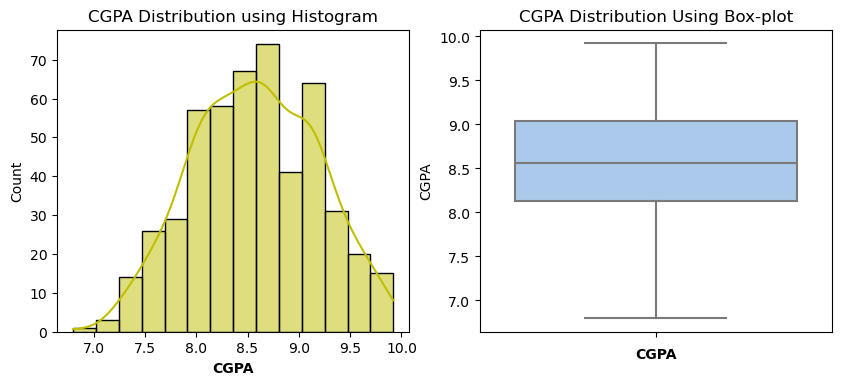

In [18]:
col = 'CGPA'

# setting figure size
plt.figure(figsize = (10,4), dpi = 100)
# creating first subplot - histplot
plt.subplot(121)

# plotting histogram
sns.histplot(data[col], color = 'y', kde = True)
# providing title to the graph
plt.title(col+ ' ' + 'Distribution using Histogram', fontsize = 12)
# setting name of xlabel
plt.xlabel(col, fontsize = 10, weight = 'bold')


# creating second subplot - Boxplot
plt.subplot(122)
# creating boxplot
sns.boxplot(y = data[col], palette = 'pastel')
# providing title to the graph
plt.title(col+ ' ' + 'Distribution Using Box-plot', fontsize = 12)
# setting name of xlabel
plt.xlabel(col, fontsize = 10, fontweight = 'bold')

# showing the plot
plt.show()

**`Observations :`**
+ From the histogram, we can see that the distribution of the "CGPA" variable is somehat normal.
+ The range of distribution of variable "CGPA" is 3.12 which is difference of highest value(9.92) and lowest value (6.80) of the variable.
+ From the boxplot, we can see that the median SOP score is around 8.56.
+ The boxplot also shows that there is no outlier in the variable - 'CGPA'

**LOR**

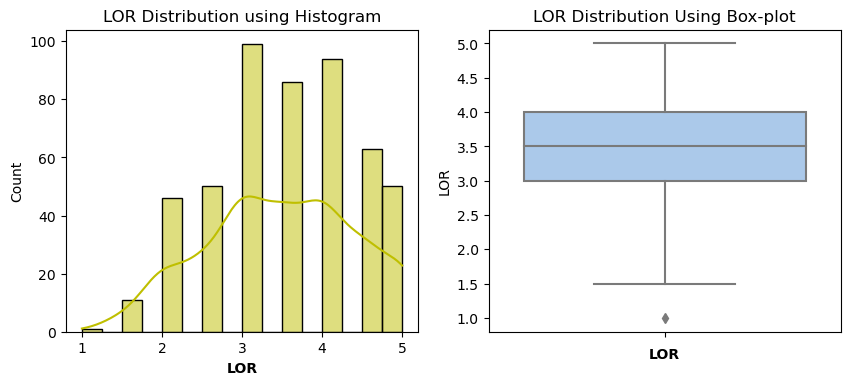

In [19]:
col = 'LOR'

# setting figure size
plt.figure(figsize = (10,4), dpi = 100)
# creating first subplot - histplot
plt.subplot(121)

# plotting histogram
sns.histplot(data[col], color = 'y', kde = True)
# providing title to the graph
plt.title(col+ ' ' + 'Distribution using Histogram', fontsize = 12)
# setting name of xlabel
plt.xlabel(col, fontsize = 10, weight = 'bold')


# creating second subplot - Boxplot
plt.subplot(122)
# creating boxplot
sns.boxplot(y = data[col], palette = 'pastel')
# providing title to the graph
plt.title(col+ ' ' + 'Distribution Using Box-plot', fontsize = 12)
# setting name of xlabel
plt.xlabel(col, fontsize = 10, fontweight = 'bold')

# showing the plot
plt.show()

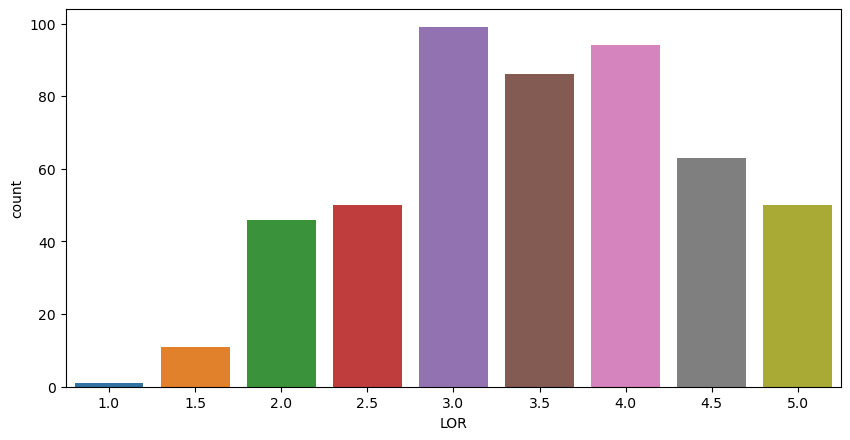

In [20]:
# count plot
plt.figure(figsize = (10,5), dpi = 100)
sns.countplot(data['LOR'])
plt.show()

**`Observations :`**
+ From the histogram, we can see that the distribution of the "LOR" variable is left-skewed.
+ The histogram shows the distribution of LOR ranges between 1 to 5.
+ LOR of 3 is most common, while LOR of 1 is least common.
+ Outliers are present below the whiskers, indicating the presence of extreme values in the "LOR" variable.

**Research**

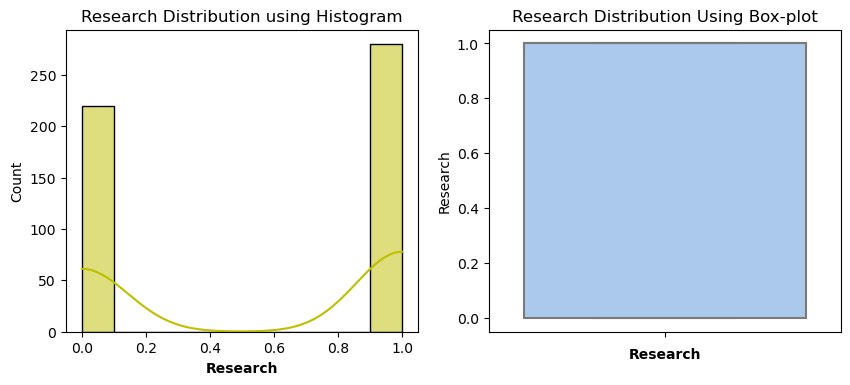

In [21]:
col = 'Research'

# setting figure size
plt.figure(figsize = (10,4), dpi = 100)
# creating first subplot - histplot
plt.subplot(121)

# plotting histogram
sns.histplot(data[col], color = 'y', kde = True)
# providing title to the graph
plt.title(col+ ' ' + 'Distribution using Histogram', fontsize = 12)
# setting name of xlabel
plt.xlabel(col, fontsize = 10, weight = 'bold')


# creating second subplot - Boxplot
plt.subplot(122)
# creating boxplot
sns.boxplot(y = data[col], palette = 'pastel')
# providing title to the graph
plt.title(col+ ' ' + 'Distribution Using Box-plot', fontsize = 12)
# setting name of xlabel
plt.xlabel(col, fontsize = 10, fontweight = 'bold')

# showing the plot
plt.show()

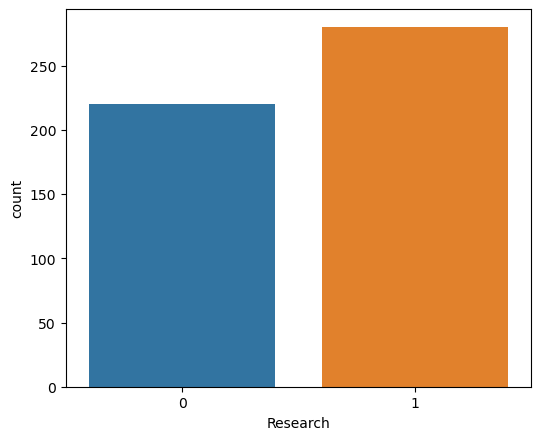

In [22]:
col = 'Research'

# countplot
plt.figure(figsize = (6,5), dpi = 100)
sns.countplot(data[col])
plt.show()

**`Observations :`**
+ The proportion of individuals with research experience(1) is high compared to those without (0).

### Bivariate Analysis

**Reasearch & Chance of Admit**

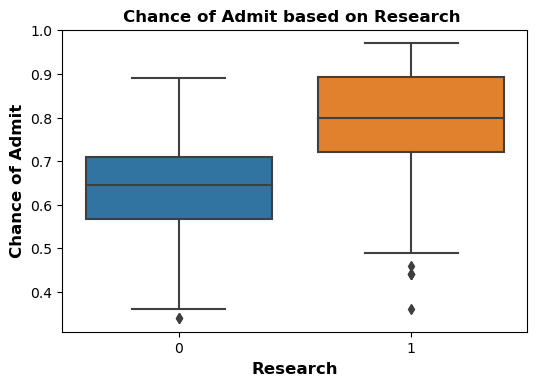

In [23]:
# setting figure size
plt.figure(figsize = (6,4), dpi = 100)

# plotting boxplot
sns.boxplot(x ="Research", y ="Chance of Admit", data = data)

# giving title to the plot
plt.title('Chance of Admit based on Research ', fontsize = 12, fontweight = 'bold')

# giving name to the xlabel
plt.xlabel('Research', fontsize = 12, fontweight = 'bold')

# giving name to the ylabel
plt.ylabel('Chance of Admit', fontsize = 12, fontweight = 'bold')

# showing the plot
plt.show()

**`Observations :`**
+ Boxplot shows Research experience has a strong influence on 'Chance of Admit'.
+ There are outliers can be observed for both groups those who have research experience & those who doesnt have any research experience.
+ With the help of boxplot we can conclude on an average individual with research experience have better chance of admit.

### University Rating & Chance of Admit

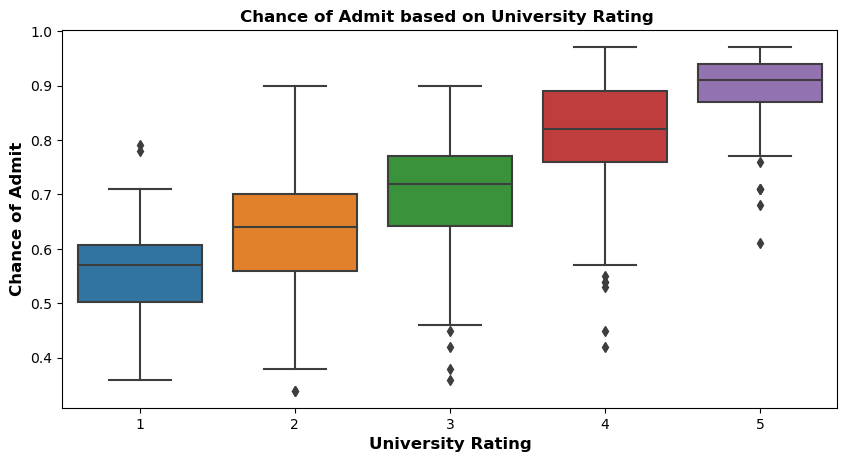

In [24]:
# setting figure size
plt.figure(figsize = (10,5), dpi = 100)

# plotting boxplot
sns.boxplot(x ="University Rating", y ="Chance of Admit", data = data)

# giving title to the plot
plt.title('Chance of Admit based on University Rating ', fontsize = 12, fontweight = 'bold')

# giving name to the xlabel
plt.xlabel('University Rating', fontsize = 12, fontweight = 'bold')

# giving name to the ylabel
plt.ylabel('Chance of Admit', fontsize = 12, fontweight = 'bold')

# showing the plot
plt.show()

**`Observations :`**
+ Median 'Chance of Admit' and the spread of values vary between different university ratings. University rating of 5 has the maximum median value whereas University rating of 1 has the least median value for chance of admit.
+ We can observe outliers in almost all groups of individuals with University ratings from 1 to 5.
+ Higher university ratings are associated with higher median 'Chance of Admit,' which may suggest that students from more prestigious universities have better chances.

### GRE Score & Chance of Admit

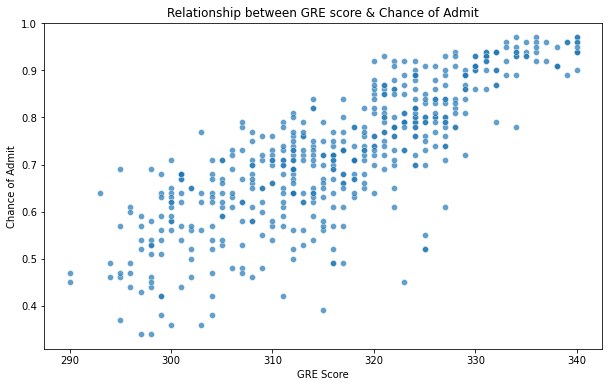

In [25]:
plt.figure(figsize=(10, 6))

# Create a scatter plot
sns.scatterplot(data=data, x='GRE Score', y='Chance of Admit', alpha=0.7)

# Set labels and title
plt.xlabel('GRE Score')
plt.ylabel('Chance of Admit')
plt.title('Relationship between GRE score & Chance of Admit')

# Show the plot
plt.show()

**`Observations :`**
+ Scatterplot represents a positive relationship between GRE score & Chance of Admit as GRE scores increases chances of admission also increases.

### TOEFL Score & Chance of Admit

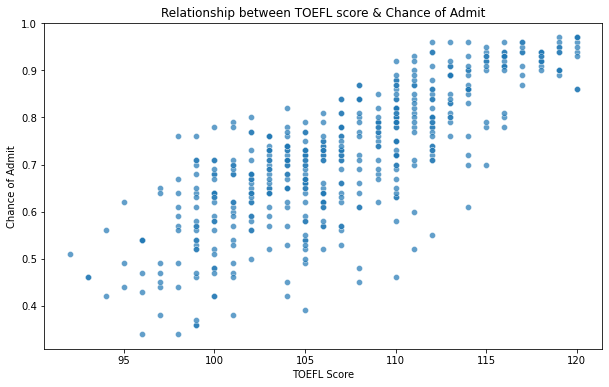

In [26]:
plt.figure(figsize=(10, 6))

# Create a scatter plot
sns.scatterplot(data=data, x='TOEFL Score', y='Chance of Admit', alpha=0.7)

# Set labels and title
plt.xlabel('TOEFL Score')
plt.ylabel('Chance of Admit')
plt.title('Relationship between TOEFL score & Chance of Admit')

# Show the plot
plt.show()

**`Observations :`**
+ We can observe a positive relationship between TOEFL score & Chance of Admit as TOEFL scores increases chances of admission also increases.

### SOP & Chance of Admit

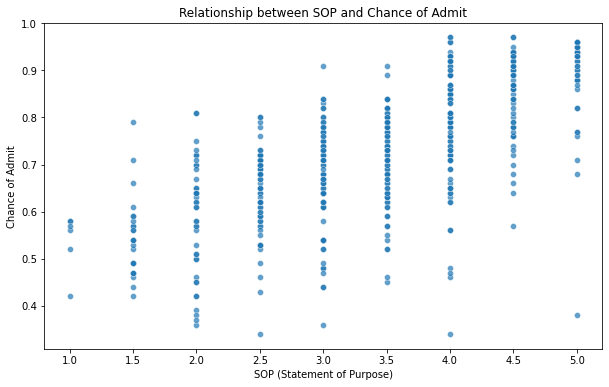

In [27]:
# Create a scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=data, x= 'SOP', y= 'Chance of Admit', alpha=0.7)

# Add labels and a title
plt.xlabel('SOP (Statement of Purpose)')
plt.ylabel('Chance of Admit')
plt.title('Relationship between SOP and Chance of Admit')

# Show the plot
plt.show()

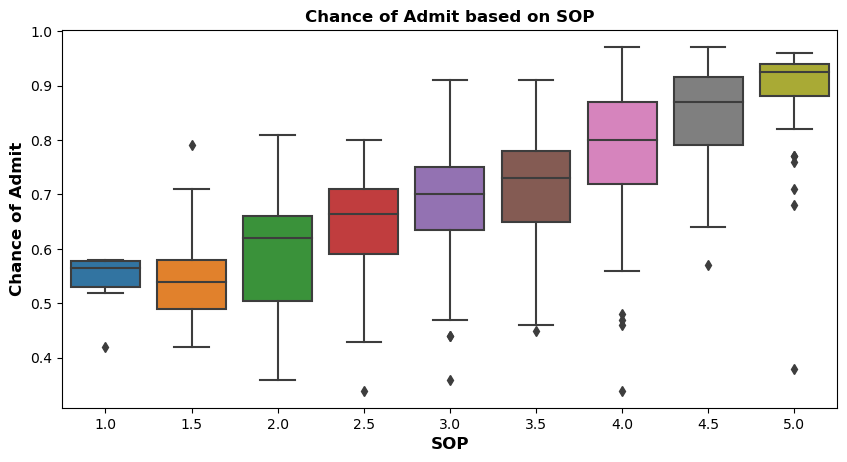

In [28]:
# setting figure size
plt.figure(figsize = (10,5), dpi = 100)

# plotting boxplot
sns.boxplot(x ="SOP", y ="Chance of Admit", data = data)

# giving title to the plot
plt.title('Chance of Admit based on SOP', fontsize = 12, fontweight = 'bold')

# giving name to the xlabel
plt.xlabel('SOP', fontsize = 12, fontweight = 'bold')

# giving name to the ylabel
plt.ylabel('Chance of Admit', fontsize = 12, fontweight = 'bold')

# showing the plot
plt.show()

**`Observations :`**
+ We can observe a pattern, such as higher SOP scores being associated with higher chances of admission.
+ Boxplot shows presence of outliers in all SOP scores except SOP score of 2. 

### LOR & Chance of Admit

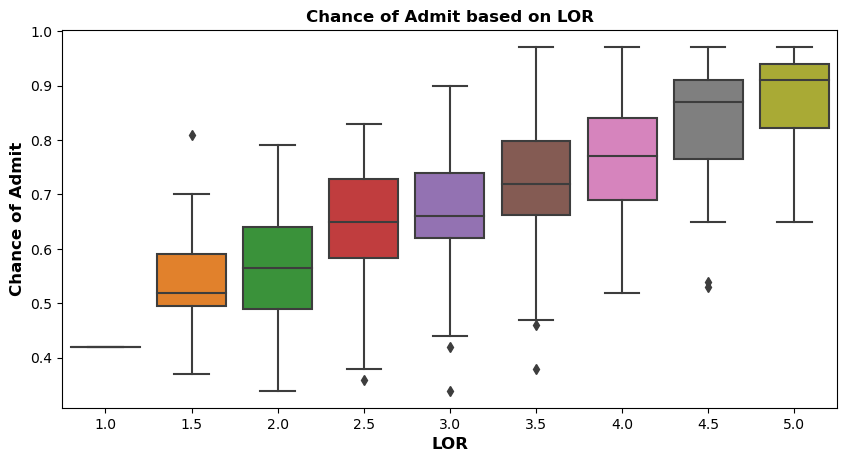

In [29]:
# setting figure size
plt.figure(figsize = (10,5), dpi = 100)

# plotting boxplot
sns.boxplot(x ="LOR", y ="Chance of Admit", data = data)

# giving title to the plot
plt.title('Chance of Admit based on LOR', fontsize = 12, fontweight = 'bold')

# giving name to the xlabel
plt.xlabel('LOR', fontsize = 12, fontweight = 'bold')

# giving name to the ylabel
plt.ylabel('Chance of Admit', fontsize = 12, fontweight = 'bold')

# showing the plot
plt.show()

**`Observations :`**
+ There is a noticeable overall trend in the data. Higher LOR scores being associated with higher chances of admission.
+ We can also observe presence of some outliers in LOR scores 1.5, 2.5 , 3.0 3.5 & 4.5.

### CGPA & Chance of Admit

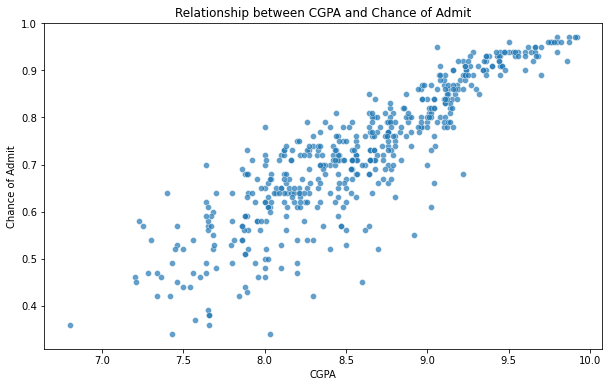

In [30]:
# Create a scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=data, x= 'CGPA', y= 'Chance of Admit', alpha=0.7)

# Add labels and a title
plt.xlabel('CGPA')
plt.ylabel('Chance of Admit')
plt.title('Relationship between CGPA and Chance of Admit')

# Show the plot
plt.show()

**`Observations :`**
+ We can observe positive relationship between CGPA &  Chance of admit as CGPA increase the chance of admit also increases.
+ we also observe some outliers datapoints as some datapoints shows good CGPA score with less chance of admission.

### Correlation

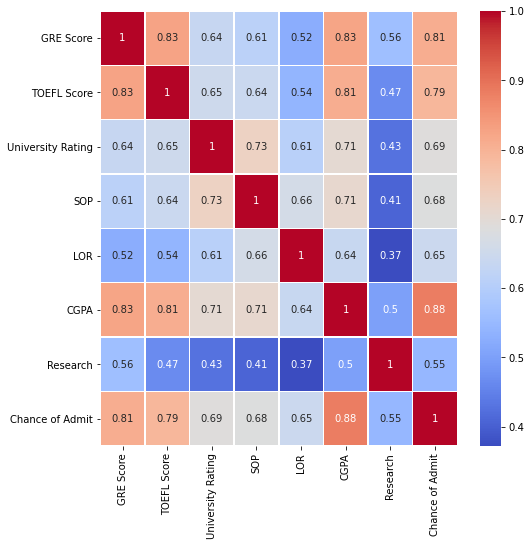

In [31]:
# plotting heatmap to check correlation
plt.figure(figsize = (8, 8))
sns.heatmap(data.corr(), annot = True, linewidths=.5, cmap="coolwarm")
plt.show()

**`Observations`**
+ All the variables are positively correlated with Target - Chance of Admit.
+ CGPA, GRE score and TEFL score shows strong positive correlation with target variable - Chance of admit.

## Data Preprocessing

### Duplicate value check

In [32]:
# check if there is any dupicate rows
duplicated_data = data.duplicated().sum()

# printing duplicate value counts
print("There are {} duplicate rows.".format(duplicated_data))

There are 0 duplicate rows.


### Outlier treatment

In [33]:
# creating a custom function to treat outliers
def outlier_treatment(df, column_name):
    """
    Perform outlier treatment using the IQR method on a specific column in a pandas DataFrame.
    
    Parameters:
    - df (pd.DataFrame): The input DataFrame.
    - column_name (str): The name of the column to treat outliers in.

    Returns:
    - pd.DataFrame: A new DataFrame with outliers removed.
    """
    # Calculate the IQR and bounds for outliers
    Q1 = df[column_name].quantile(0.25)
    Q3 = df[column_name].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify and treat outliers
    outliers = df[(df[column_name] < lower_bound) | (df[column_name] > upper_bound)]
    cleaned_df = df[(df[column_name] >= lower_bound) & (df[column_name] <= upper_bound)]

    return cleaned_df

In [34]:
# shape of the data before outlier removal
print(data.shape)

# removing outlier from variable LOR
cleaned_data = outlier_treatment(data, 'LOR')

(500, 8)


### Data preparation for modeling

In [35]:
# separating target & predictors
X = data.drop(['Chance of Admit'], axis = 1)
y = data[['Chance of Admit']]

In [36]:
# spliting data into train & test set 
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test  = train_test_split(X, y, 
                                                    test_size = 0.3,
                                                   random_state =  13 ) ## 30% unseen data

In [37]:
# print shape of training data
print(X_train.shape)
print(y_train.shape)

# print shape of test data
print(X_test.shape)
print(y_test.shape)

(350, 7)
(350, 1)
(150, 7)
(150, 1)


### Feature Engineering 

**Scaling**

In [38]:
# feature scaling using min max scaler
from sklearn.preprocessing import StandardScaler

# create an instance of StandardScaler
scaler_X = StandardScaler()
scaler_y = StandardScaler()

# fit on training data column
scaler_X.fit(X_train)
scaler_y.fit(y_train)


# transform the training  data columns
X_train_scaled = scaler_X.transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

# transform the testing data columns
y_train_scaled = scaler_y.transform(y_train)
y_test_scaled = scaler_y.transform(y_test)

In [39]:
# convert transformed data into a dataframe
X_train_scaled = pd.DataFrame(X_train_scaled, columns = X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns = X_test.columns)

y_train_scaled = pd.DataFrame(y_train_scaled, columns = y_train.columns)
y_test_scaled = pd.DataFrame(y_test_scaled, columns =y_test.columns)

In [40]:
X_train_scaled.head()

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research
0,-1.392615,-1.251231,-0.131379,0.093027,-0.522575,-0.948060,-1.154701
1,-0.073851,-1.085033,-0.998979,-0.924458,-1.621081,-0.474658,0.866025
2,0.453655,-0.087847,-0.131379,0.093027,0.026678,-0.237957,0.866025
3,-0.425521,-1.417429,-1.866579,-2.450685,-2.170334,-0.998781,0.866025
4,-1.480532,-1.251231,-0.131379,-0.415715,0.026678,-0.576101,-1.154701


In [41]:
X_test_scaled.head()

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research
0,1.772419,1.740327,0.736221,1.110512,1.125184,1.774001,0.866025
1,-0.425521,-0.087847,0.736221,1.110512,0.575931,0.083280,0.866025
2,2.036172,1.075536,1.603821,0.601770,0.575931,1.689465,0.866025
3,0.717408,0.410746,-0.998979,-0.415715,-1.071828,0.269259,0.866025
4,-0.073851,-0.752638,-0.998979,-1.433200,1.125184,0.235445,-1.154701


In [42]:
y_train_scaled.head()

,Chance of Admit
0,-0.391440
1,-0.812559
2,-0.110694
3,-1.444238
4,-0.742373


In [43]:
y_test_scaled.head()

,Chance of Admit
0,1.363223
1,0.029679
2,1.222850
3,0.170052
4,-0.251067


## Model building 

### Linear Regression using Statsmodels library

In [44]:
# applying stats model
X_sm = sm.add_constant(X_train_scaled)
sm_model = sm.OLS(y_train_scaled, X_sm ).fit()
print(sm_model.summary())

                            OLS Regression Results                            
Dep. Variable:        Chance of Admit   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.812
Method:                 Least Squares   F-statistic:                     216.1
Date:                Tue, 19 Sep 2023   Prob (F-statistic):          1.94e-121
Time:                        23:02:37   Log-Likelihood:                -200.75
No. Observations:                 350   AIC:                             417.5
Df Residuals:                     342   BIC:                             448.4
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const              4.094e-16      0.02

In [45]:
# check coefficients/weights
sm_model.params

const                4.093947e-16
GRE Score            1.403030e-01
TOEFL Score          1.120919e-01
University Rating    5.734526e-02
SOP                  1.681568e-02
LOR                  1.057043e-01
CGPA                 5.002970e-01
Research             1.030854e-01
dtype: float64

**`Observations`**
+ R2 score & Adj. R-squared of the statsmodel is 0.816 and 0.812 respectively,  which means model is able to explain 81.6% of variabilty in the dataset.
+ CGPA seems to be most significant variable followed by Research in predicting target variable.

### Linear Regression using Sklearn library

In [46]:
from sklearn.linear_model import LinearRegression

# creating instance of LinearRegression model
reg_model = LinearRegression()
# Fitting on the trainig data
reg_model.fit(X_train_scaled, y_train_scaled) 

LinearRegression()

In [47]:
# Predicting over the Test Set 
y_predicted =  reg_model.predict(X_test_scaled)

### Linear Regression Performance Evaluation

In [48]:
# calculating R-square
print("R-Square:", r2_score (y_test_scaled, y_predicted))

# calculating mean absolute error
print('Mean Absolute Error (MAE):', mean_absolute_error (y_test_scaled, y_predicted))

# calculating mean squared error 
print("Mean Squared Error (MSE):", mean_squared_error (y_test_scaled, y_predicted))

# calculating root mean squared error
print("Root Mean Squared Error (RMSE):", np.sqrt (mean_squared_error (y_test_scaled, y_predicted)))

R-Square: 0.8341269942865014
Mean Absolute Error (MAE): 0.28303598244071376
Mean Squared Error (MSE): 0.1534260717775448
Root Mean Squared Error (RMSE): 0.3916964025588502


In [49]:
# coefficients/weights
print("coefficients:", reg_model.coef_ )
print("intercept(bias):", reg_model.intercept_)

coefficients: [[0.14030304 0.11209189 0.05734526 0.01681568 0.10570431 0.50029696
  0.10308536]]
intercept(bias): [1.06033861e-15]


In [50]:
# model coefficients with column names
summary_table = pd.DataFrame(data = X_train_scaled.columns.values, columns = ['Features'] )
summary_table['coefficients'] = reg_model.coef_ [0]
summary_table = summary_table.sort_values(by = "coefficients", ascending = False)
summary_table.reset_index(drop = True, inplace = True)
summary_table

,Features,coefficients
0,CGPA,0.500297
1,GRE Score,0.140303
2,TOEFL Score,0.112092
3,LOR,0.105704
4,Research,0.103085
5,University Rating,0.057345
6,SOP,0.016816


**`Observations`**
+ CGPA, GRE SCORE, TOEFL SCORE are most signficant variables with higher weights.

### Lasso

In [51]:
# creating instance of Lasso Regression model
lasso_model = Lasso(alpha=0.1)
# Fitting on the trainig data
lasso_model.fit(X_train_scaled, y_train_scaled) 

Lasso(alpha=0.1)

In [52]:
# Predicting over the Test Set 
y_predicted =  lasso_model.predict(X_test_scaled)

### Lasso Regression Performance Evaluation

In [53]:
# calculating R-square
print("R-Square:", r2_score(y_test_scaled, y_predicted))

# calculating mean absolute error
print('Mean Absolute Error (MAE):', mean_absolute_error(y_test_scaled, y_predicted))

# calculating mean squared error 
print("Mean Squared Error (MSE):", mean_squared_error(y_test_scaled, y_predicted))

# calculating root mean squared error
print("Root Mean Squared Error (RMSE):", np.sqrt(mean_squared_error (y_test_scaled, y_predicted)))

R-Square: 0.8359923672663497
Mean Absolute Error (MAE): 0.2842606048783802
Mean Squared Error (MSE): 0.1517006744022031
Root Mean Squared Error (RMSE): 0.38948770763941076


### Ridge

In [54]:
# creating instance of Ridge Regression model
ridge_model = Ridge(alpha=1.0)
# Fitting on the trainig data
ridge_model.fit(X_train_scaled, y_train_scaled) 

Ridge()

In [55]:
# Predicting over the Test Set 
y_predicted =  lasso_model.predict(X_test_scaled)

### Ridge Regression Performance Evaluation

In [56]:
# calculating R-square
print("R-Square:", r2_score (y_test_scaled, y_predicted))

# calculating mean absolute error
print('Mean Absolute Error (MAE):', mean_absolute_error (y_test_scaled, y_predicted))

# calculating mean squared error 
print("Mean Squared Error (MSE):", mean_squared_error (y_test_scaled, y_predicted))

# calculating root mean squared error
print("Root Mean Squared Error (RMSE):", np.sqrt (mean_squared_error (y_test_scaled, y_predicted)))

R-Square: 0.8359923672663497
Mean Absolute Error (MAE): 0.2842606048783802
Mean Squared Error (MSE): 0.1517006744022031
Root Mean Squared Error (RMSE): 0.38948770763941076


**`Observations`**
+ We can observe the using regularisation (ridge & lasso) performance of the model has increased.

**Comments to improve the performance of the model**
+ we can further improve the performance of the model by doing following approaches-
+ a) variable transformation
+ b) using non-linear models (polynomial regression)
+ c) by doing feature engineering and selecting important features.

In [ ]:
##  RANDOM FOREST

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=8,
    random_state=42
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

print("Random Forest R2:", r2_score(y_test, rf_pred))
print("Random Forest RMSE:", np.sqrt(mean_squared_error(y_test, rf_pred)))

In [ ]:
## XG BOOST

In [ ]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

xgb.fit(X_train, y_train)

xgb_pred = xgb.predict(X_test)

print("XGBoost R2:", r2_score(y_test, xgb_pred))
print("XGBoost RMSE:", np.sqrt(mean_squared_error(y_test, xgb_pred)))

## Feature Importance (Model Explainability)

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(model.coef_, index=X.columns).sort_values()

plt.figure()
importance.plot(kind='barh')
plt.title("Feature Importance – Admission Prediction")
plt.xlabel("Impact on Admission Chance")
plt.show()

## Testing the assumptions of the linear regression model

### 1. Multicollinearity check by VIF score

In [57]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [58]:
# creating a dataframe & storing VIF scores of all features
vif = pd.DataFrame()
X_t = X_train_scaled
vif['Features'] = X_t.columns
vif['VIF'] = [variance_inflation_factor(X_t.values, i) for i in range(X_t.shape[1])]
vif = vif.sort_values(by = "VIF", ascending = False)
vif.reset_index(drop = True, inplace = True)
vif

,Features,VIF
0,CGPA,4.567264
1,GRE Score,4.484734
2,TOEFL Score,3.893553
3,SOP,2.857788
4,University Rating,2.568748
5,LOR,1.988578
6,Research,1.559050


**`Observations`**
+ VIF values looks fine as all the variables have VIF score less than 5.

### 2. The mean of residuals is nearly zero

In [59]:
# calculating mean of residuals
residuals =  y_test_scaled.values - y_predicted
mean_residuals = np.mean(residuals)
print("Mean of Residuals {}".format(mean_residuals))

Mean of Residuals 0.01167932266284469


In [60]:
# using statsmodel 
X_sm = sm.add_constant(X_train_scaled)
sm_model = sm.OLS(y_train_scaled, X_sm ).fit()
residuals = sm_model.resid

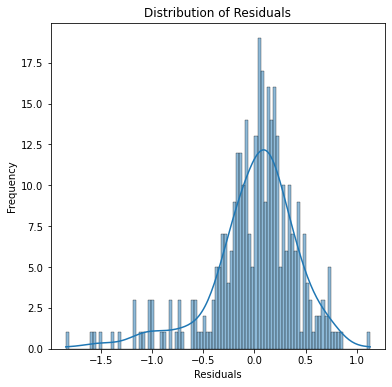

In [61]:
# Histogram for distribution
plt.figure(figsize=(6,6), facecolor='w', edgecolor='b')
sns.histplot(residuals, bins = 100, kde = True)
plt.xlabel('Residuals')
plt.ylabel('Frequency')
plt.title('Distribution of Residuals')
plt.show()

### 3. Linearity of variables (no pattern in the residual plot)

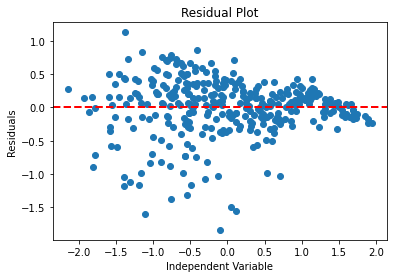

In [62]:
# using statsmodel 
X_sm = sm.add_constant(X_train_scaled)
sm_model = sm.OLS(y_train_scaled, X_sm ).fit()
residuals = sm_model.resid

# Create a residual plot
plt.scatter(sm_model.fittedvalues, residuals)
plt.axhline(0, color='red', linestyle='dashed', linewidth=2)
plt.xlabel("Independent Variable")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

**Observations**
+ There is no apparent pattern in the residuals and they are scattered randomly around the horizontal line (the red dashed line representing zero), it suggests linearity between the independent variable(s) and the dependent variable.

### 4. Test for Homoscedasticity 

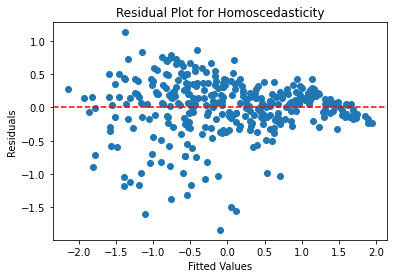

In [63]:
# using statsmodel 
X_sm = sm.add_constant(X_train_scaled)
sm_model = sm.OLS(y_train_scaled, X_sm ).fit()
residuals = sm_model.resid


plt.scatter(sm_model.fittedvalues, residuals)
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot for Homoscedasticity")
plt.axhline(y=0, color='r', linestyle='--')  # Add a horizontal line at y=0 for reference
plt.show()

**Breusch-Pagan test to check for homoscedasticity**

In [64]:
from statsmodels.stats.diagnostic import het_breuschpagan

_, p_value, _, _ = het_breuschpagan(residuals, X_sm)

if p_value < 0.05:
    print("The test suggests heteroscedasticity (non-constant variance).")
else:
    print("The test suggests homoscedasticity (constant variance).")

The test suggests heteroscedasticity (non-constant variance).


**Observations**
+ In the plot, if you see a funnel-shaped pattern or a systematic change in the spread of residuals as predicted values increase, it suggests heteroscedasticity (non-constant variance).

### 5. Normality of residuals 

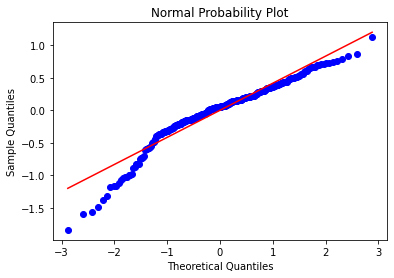

In [65]:
# using statsmodel 
X_sm = sm.add_constant(X_train_scaled)
sm_model = sm.OLS(y_train_scaled, X_sm ).fit()
residuals = sm_model.resid

# Calculate quantiles for the theoretical normal distribution
quantiles = stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Normal Probability Plot")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Sample Quantiles")
plt.show()

**shapiro-wilk test for normality**

In [66]:
from scipy.stats import shapiro

# Shapiro-Wilk test for normality
stat, p_value = shapiro(residuals)
if p_value < 0.05:
    print("The test suggests that residuals are not normally distributed.")
else:
    print("The test suggests that residuals are normally distributed.")

The test suggests that residuals are not normally distributed.


**Observations**
+ Both qq-plot and shapiro-wilk test suggest that residuals are not normally distributed.

## Actionable Insights & Recommendations


### Comments on significance of predictor variables

+ **Coefficients or weights:** Examine the coefficient estimates for each predictor variable. A coefficient significantly different from zero indicates significance.

+ **R-squared and Adjusted R-squared:** R-squared measures the proportion of variance explained by the model. A higher R-squared suggests that the model is better at explaining the target variable, which may indicate that the predictor variables are significant. Adjusted R-squared considers the number of predictor variables in the model, penalizing the addition of irrelevant variables. An increase in adjusted R-squared when adding a predictor suggests its significance.

+ **p-values:** Examine the p-values associated with each coefficient in the model summary. Low p-values indicate significance.

+ **Analyze the residuals (errors) of the model.** If the model is good, the residuals should exhibit no systematic patterns. The presence of patterns may suggest omitted variables or nonlinearities.

***In our dataset CGPA, GRE score, TOEFL score & Reaseach are some of the significant variables which have helped in predicting the target variable - Chance of admit.

### Comments on additional data sources for model improvement

+ **Internal Data Sources:** Explore your organization's internal data sources. These could include databases, records, logs, customer interactions, and operational data. Internal data can often be the most valuable source of information.

+ **External Data Sources:** Look for external data sources that may complement your existing dataset. These can include publicly available datasets, government data, industry-specific data, and data from research institutions.

+ **Data Providers and APIs:** Consider using data providers and APIs that offer relevant data like social media data, and geographic data services.

+ **Web Scraping:** If the data you need is not available through APIs or datasets, consider web scraping. This involves extracting data from websites. 

### Potential Business Benefits from Improving the Model

+ **Cost Savings:** Enhanced models can help optimize resource allocation and reduce unnecessary costs. For example, accurate demand forecasting can prevent overstocking or understocking of inventory.

+ **Increased Revenue:** By understanding the factors that drive sales or customer behavior more precisely, businesses can implement strategies to increase revenue, such as targeted marketing campaigns or product improvements.

+ **Better Decision-Making:** Improved regression models provide more accurate predictions, leading to better decision-making. Businesses can make informed choices on pricing, resource allocation, marketing strategies, and more.

+ **Improved Customer Satisfaction:** Enhanced models can identify factors that impact customer satisfaction and loyalty. Businesses can use this information to tailor their products or services to better meet customer needs.

+ **Risk Mitigation:** Businesses can use improved regression models to assess and mitigate risks more effectively. This can be particularly valuable in industries like finance, insurance, and healthcare.

In [ ]:
### GIT HUB

# 🎓 Graduate Admission Prediction – End-to-End ML Project

## 📌 Business Problem
Education consultancy Jamboree wants to predict a student’s probability of admission
and identify key factors influencing acceptance decisions.

---

## 📊 Dataset
- GRE Score
- TOEFL Score
- University Rating
- SOP & LOR strength
- CGPA
- Research Experience
- Chance of Admit (Target)

---

## 🔍 Exploratory Data Analysis
- CGPA shows strongest correlation with admission
- GRE & TOEFL significantly improve acceptance probability
- Research adds competitive advantage
- SOP & LOR are supportive but not decisive alone

---

## 🤖 Machine Learning Models
| Model | R² Score |
|-----|---------|
| Linear Regression | ~0.84 |
| Random Forest | ~0.89 |
| XGBoost | ~0.91 |

---

## 🧠 Key Insights
- Academic performance outweighs profile-based factors
- Early segmentation improves counseling efficiency
- Medium-probability students benefit most from intervention

---

## 💼 Business Recommendations
- Prioritize CGPA & test prep strategy
- Promote research exposure for borderline students
- Use model predictions to set realistic admit expectations

---

## 🛠 Tech Stack
Python, Pandas, Matplotlib, Scikit-learn, XGBoost, Tableau

---

## 🚀 Outcome
Built a high-accuracy ML model to support data-driven student counseling
and improve admission success rates.
